# The goal here is to replicate the Vision Transformer(ViT) paper into usable code.
## Paper Link : https://arxiv.org/abs/2010.11929

In [169]:
import torch
import torchvision
import pathlib
import matplotlib.pyplot as plt
from going_modular import data_setup, engine
from helper_functions import plot_loss_curves
from torchinfo import summary
from torch import nn
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from pathlib import Path
from torchvision import transforms
from PIL import Image
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [4]:
# Setup device agnostic code
device =  "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## 1. Get Data

In [5]:
data_path = Path("data")
image_path = data_path/ "applepie_fries_icecream_20_percent"

In [6]:
train_dir = image_path/"train"
test_dir = image_path/"test"

## 2. Create dataset and dataloader

In [7]:
import os
from pathlib import Path

def find_classes(directory):
    classes = sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())
    if not classes:
        raise FileNotFoundError(f"No class folders found in {directory}")
    class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
    return classes, class_to_idx

In [8]:
class ImageFolderCustom(Dataset):
    def __init__(self, targ_dir: str, transform=None):
        self.paths = list(pathlib.Path(targ_dir).glob("*/*.jpg"))
        self.transform = transform
        self.classes, self.classes_to_idx = find_classes(targ_dir)

    def load_image(self, index):
        return Image.open(self.paths[index]).convert("RGB")

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        img = self.load_image(index)
        class_name = self.paths[index].parent.name
        class_idx = self.classes_to_idx[class_name]

        if self.transform:
            return self.transform(img), class_idx
        return img, class_idx

In [13]:
# Manual Transforms to match the Vit Paper 
manual_transforms = transforms.Compose([transforms.Resize((224,224)),
                                       transforms.ToTensor(),
                                       transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)])


In [14]:
train_data = ImageFolderCustom(targ_dir=train_dir, transform=manual_transforms)
test_data = ImageFolderCustom(targ_dir=test_dir, transform=manual_transforms)
class_names = train_data.classes

In [15]:
# Create dataloader 
train_dataloader = DataLoader(dataset=train_data,
                             batch_size=32,
                             num_workers=0,
                             shuffle=True)
test_dataloader = DataLoader(dataset=test_data,
                            batch_size=32,
                            num_workers=0,
                            shuffle=False)

In [16]:
len(train_dataloader), len(test_dataloader), class_names

(15, 5, ['apple_pie', 'french_fries', 'ice_cream'])

### 2.1 Vizualise a single image

In [76]:
image_batch, label_batch = next(iter(train_dataloader))

# Get a single image and label from the batch
image, label = image_batch[0], label_batch[0]

image.shape, label


(torch.Size([3, 224, 224]), tensor(0))

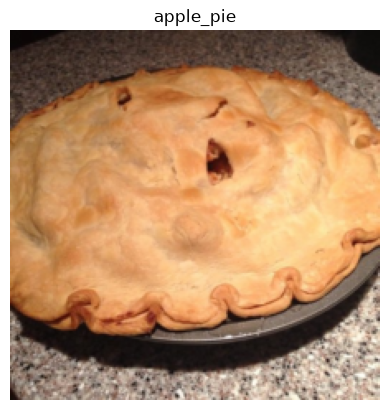

In [77]:
image_show = (image * 0.5 + 0.5).clamp(0,1)
plt.imshow(image_show.permute(1,2,0))  # matplotlib needs color channel at last so 1,2,0
plt.title(class_names[label])
plt.axis(False);

## 3. Replicating ViT: Overview
### Looking at a whole machine learning research paper can be intimidating.
### So in order break it down into smaller pieces:
* **Inputs - What goes into the model?(our case that is image tensors)**
* **Outputs - What comes out of the model/layer? (our case that is classification labels)**
* **Layers - Takes an input manipulates it with a function(self-attention)**
* **Blocks - A collection of layers**
* **Model - A collection of blocks**

### 3.1 ViT overview 
* **Figure 1 in the paper - Visual overview of the architecture.**
* **Four equations - math equations which define the functions of each layer/block.**
* **Table 1/3 - different hyperparameters for the architecture/training.**
#### Figure 1
![ViT Architecture Overview](images/08-vit-paper-figure-1-architecture-overview.png)
#### Four Equations
![Four Equations](images/08-vit-paper-four-equations.png)

### Equation 1 
* **An overview of the model is depicted in Figure 1. The standard Transformer receives as input a 1D sequence of token embeddings. To handle 2D images, we reshape the image $\mathbf{x} \in \mathbb{R}^{H \times W \times C}$ into a sequence of flattened 2D patches $\mathbf{x}_p \in \mathbb{R}^{N \times\left(P^2 \cdot C\right)}$, where ( $H, W$ ) is the resolution of the original image, $C$ is the number of channels, $(P, P)$ is the resolution of each image patch, and $N=H W / P^2$ is the resulting number of patches, which also serves as the effective input sequence length for the Transformer. The Transformer uses constant latent vector size $D$ through all of its layers, so we flatten the patches and map to $D$ dimensions with a trainable linear projection (Eq. 1). We refer to the output of this projection as the patch embeddings.**
* **Position embeddings are added to the patch embeddings to retain positional information. We use standard learnable 1D position embeddings, since we have not observed significant performance gains from using more advanced 2D-aware position embeddings (Appendix D.4). The resulting sequence of embedding vectors serves as input to the encoder.**
```python
Example: x_input = [class_token, image_patch_1, image_patch_2, image_patch_N] + [class_token_pos, image_patch_1_pos, image_patch_2_pos, image_patch_N_pos]
```

### Equation 2 & 3
* **The Transformer encoder (Vaswani et al., 2017) consists of alternating layers of multiheaded selfattention (MSA, see Appendix A) and MLP blocks (Eq. 2, 3). Layernorm (LN) is applied before every block, and residual connections after every block (Wang et al., 2019; Baevski \& Auli, 2019).**
```python
#Equation 2
x_output_MSA_block = MSA_layer(LN_layer(x_input)) + x_input

#Equation 3
x_output_MLP_block = MLP_layer(LN_layer(x_output_MSA_block)) + x_output_MSA_block
```


### Equation 4
* **Similar to BERT's [class] token, we prepend a learnable embedding to the sequence of embedded patches $\left(\mathbf{z}_0^0=\mathbf{x}_{\text {class }}\right)$, whose state at the output of the Transformer encoder $\left(\mathbf{z}_L^0\right)$ serves as the image representation $\mathbf{y}$ (Eq. 4). Both during pre-training and fine-tuning, a classification head is attached to $\mathbf{z}_L^0$. The classification head is implemented by a MLP with one hidden layer at pre-training time and by a single linear layer at fine-tuning time.**
* **MLP = multilayer perceptron a feed forward neural network with X number of layers**
```python
#Equation 4
y = Linear_layer(LN_layer(x_otuput_MLP_block))

### Table 1
![Table 1](images/08-vit-paper-table-1.png)
### ViT-Base, ViT-Large, ViT-Huge
* **Layers - Number of transformer encoder layers**
* **Hidden Size D - Embedding size throughout the architecture** **(turning each image patch into 768 Dimensional vector)**
* **MLP Size - Number of hidden units/neurons in the MLP**
* **Heads - Number of multi head self attention**
* **ViTB/16=ViT-Base with image patch size 16x16**

## 4. Equation 1 : Split data into patches and creating the class, position and patch embedding
* **Layers = input -> function -> output**
* **What is the input shape?**
* **What is the output shape?**
* **Input image: $H\times{W}\times{C}$**
* **Output image: ${N \times\left(P^2 \cdot C\right)}$**,
* **where ( $H, W$ ) is the resolution of the original image, $C$ is the number of channels, $(P, P)$ is the resolution of each image patch**
* **N = number of patches = (height * width) / p^2**
* **D = Embedding dimension**
 

In [78]:
# Create example values
height = 224
width = 224
color_channels = 3
patch_size = 16

# Calculate the number of patches 
number_of_patches = int((height*width)/ patch_size**2)
number_of_patches

196

In [79]:
# Input shape
embedding_layer_input_shape = (height,width,color_channels)

#Output shape
embedding_layer_output_shape = (number_of_patches, patch_size**2 * color_channels)
embedding_layer_output_shape

(196, 768)

In [80]:
print(f"Input Shape of single 2D image:{embedding_layer_input_shape}")
print(f"Output Shape of 1D sequence of patches:{embedding_layer_output_shape}")

Input Shape of single 2D image:(224, 224, 3)
Output Shape of 1D sequence of patches:(196, 768)


### 4.1 Turning a single image into Patches using Matplotlib just for understanding 

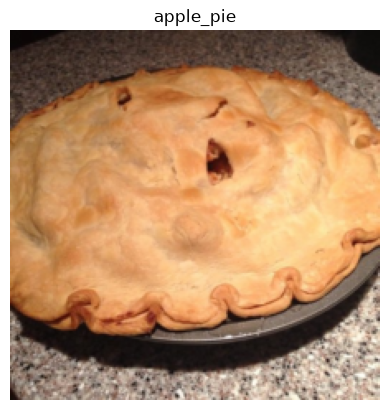

In [84]:
#View a single shape
plt.imshow(image_show.permute(1,2,0))
plt.title(class_names[label])
plt.axis(False);

In [85]:
image.shape

torch.Size([3, 224, 224])

Number of patches per row: 14        
Number of patches per column: 14        
Total patches: 196        
Patch size: 16 pixels x 16 pixels


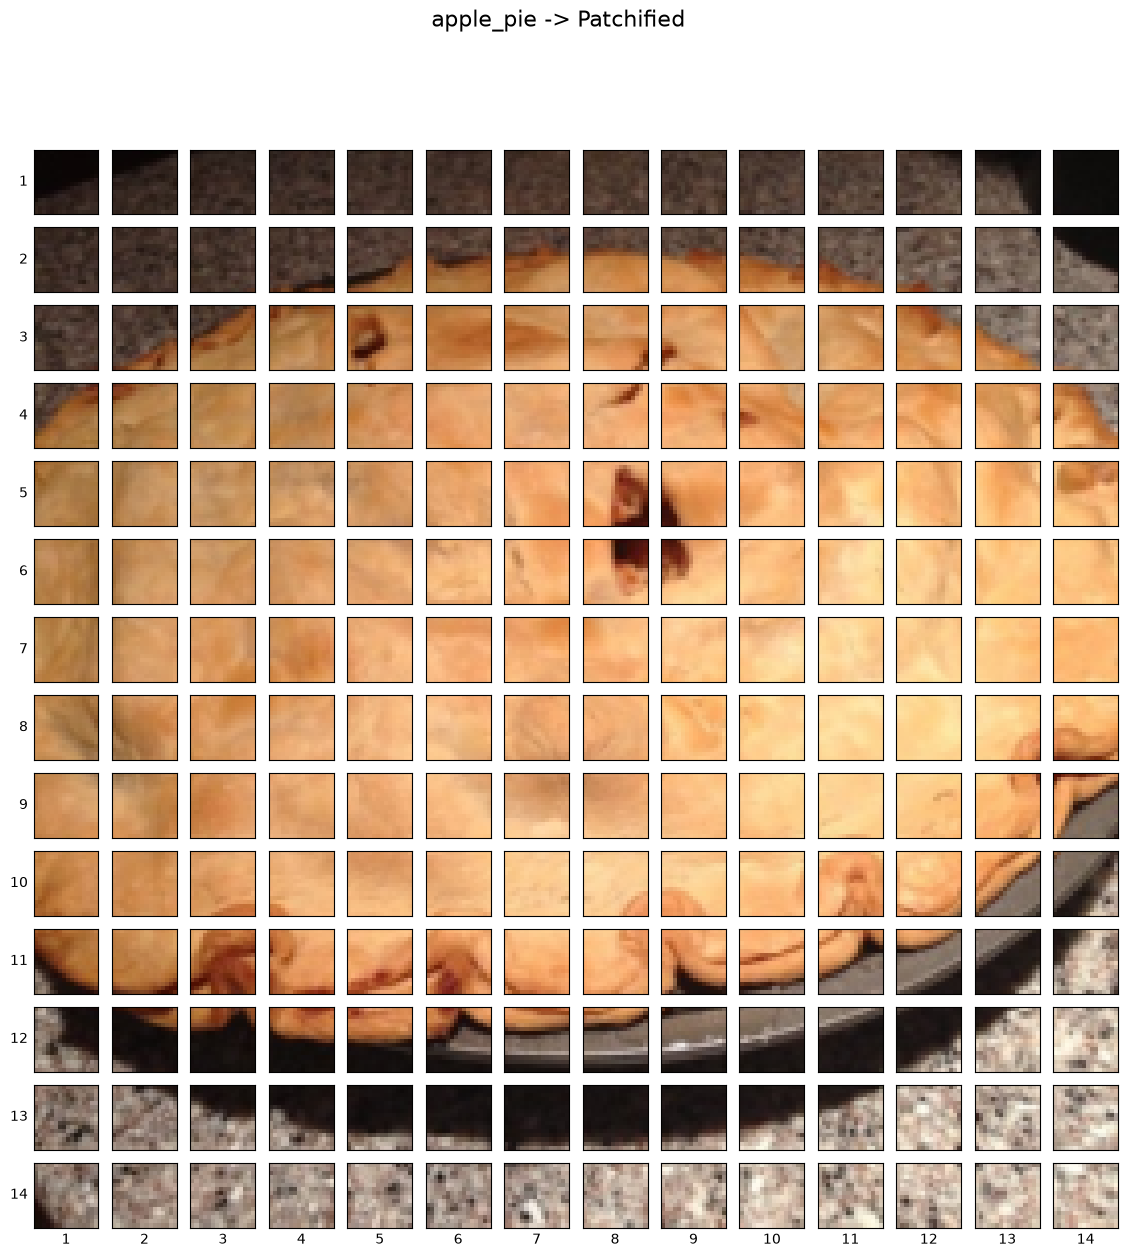

In [99]:
# Turn the above image into patches using matplotlib just to vizualized the image into patch 
# Setup hyperparameters and make sure img_size and patch_size are compatible
image_permuted = image_show.permute(1, 2, 0)
img_size = 224
patch_size = 16
num_patches = img_size//patch_size
assert img_size % patch_size == 0, "Image size must be divisible by patch size"
print(f"Number of patches per row: {num_patches}\
        \nNumber of patches per column: {num_patches}\
        \nTotal patches: {num_patches*num_patches}\
        \nPatch size: {patch_size} pixels x {patch_size} pixels")

# Create a series of subplots
fig, axs = plt.subplots(nrows=img_size // patch_size, # need int not float
                        ncols=img_size // patch_size,
                        figsize=(num_patches, num_patches),
                        sharex=True,
                        sharey=True)

# Loop through height and width of image
for i, patch_height in enumerate(range(0, img_size, patch_size)): # iterate through height
    for j, patch_width in enumerate(range(0, img_size, patch_size)): # iterate through width

        # Plot the permuted image patch (image_permuted -> (Height, Width, Color Channels))
        axs[i, j].imshow(image_permuted[patch_height:patch_height+patch_size, # iterate through height
                                        patch_width:patch_width+patch_size, # iterate through width
                                        :]) # get all color channels

        # Set up label information, remove the ticks for clarity and set labels to outside
        axs[i, j].set_ylabel(i+1, rotation="horizontal", horizontalalignment="right", verticalalignment="center")
        axs[i, j].set_xlabel(j+1)
        axs[i, j].set_xticks([])
        axs[i, j].set_yticks([])
        axs[i, j].label_outer()

# Set a super title
fig.suptitle(f"{class_names[label]} -> Patchified", fontsize=16)
plt.show()


### 4.2 Creating Image patches and turning them into patch embeddings using **`Convolutional Operations`**
#### As per ViT paper - Hybrid Architecture. As an alternative to raw image patches, the input sequence can be formed from feature maps of a CNN (LeCun et al., 1989). In this hybrid model, the patch embeddingprojection E (Eq. 1) is applied to patches extracted from a CNN feature map. As a special case,the patches can have spatial size 1x1, which means that the input sequence is obtained by simplyflattening the spatial dimensions of the feature map and projecting to the Transformer dimension. The classification input embedding and position embeddings are added as described above.


In [88]:
# Create conv2d layer to turn images into patches of learnable feature maps (embeddings)
patch_size = 16

# create a conv2d layer with hyperparameters from ViT paper 
conv2d = nn.Conv2d(in_channels=3, out_channels=768,                  # 3 for color channel and 768 that is Embedding Dim (D)
                   kernel_size=patch_size, stride=patch_size, 
                   padding=0)
conv2d

Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))

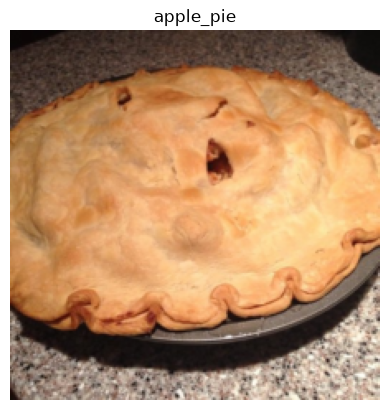

In [90]:
# View a single image 
plt.imshow(image_show.permute(1,2,0))
plt.title(class_names[label])
plt.axis(False);

#### The output of this image_out_of_conv are the feature maps

In [94]:
#Pass the image through the convolutional layer 
image_out_of_conv = conv2d(image.unsqueeze(0))     # this add batch dimension which is 32 in our case [batch size, color channel, height, width]
print(image_out_of_conv.shape)

torch.Size([1, 768, 14, 14])


### 4.3 Flatten the image using **`torch.nn.Flatten()`**

In [95]:
# Flatten out the image
flatten = nn.Flatten(start_dim=2, end_dim=3)
flatten_image = flatten(image_out_of_conv)
flatten_image

tensor([[[-0.9577, -0.7766, -0.7177,  ...,  0.3281,  0.3848,  0.2397],
         [-0.1797, -0.1398, -0.1343,  ...,  0.0899,  0.1844,  0.2332],
         [-0.4471, -0.3568, -0.3316,  ...,  0.3381,  0.3900,  0.2412],
         ...,
         [ 0.1584, -0.0051,  0.0872,  ..., -0.2790, -0.1395, -0.3849],
         [-0.2480, -0.2517, -0.2537,  ...,  0.2659,  0.3777,  0.1916],
         [-0.4743, -0.4743, -0.4727,  ...,  0.1441,  0.2091,  0.2265]]],
       grad_fn=<ViewBackward0>)

In [96]:
flatten_image.shape

torch.Size([1, 768, 196])

In [97]:
image_out_of_conv_flatten = flatten(image_out_of_conv)
image_out_of_conv_flatten.shape

torch.Size([1, 768, 196])

#### So we want: batch_size, number of patches, embedding dim)

In [98]:
image_out_of_conv_flatten.permute(0,2,1).shape

torch.Size([1, 196, 768])

### 4.4 Turning the ViT patch embedding layer into a PyTorch mode

#### We want this module to few things that is:
* **1. Create a class called **`PatchEmbedding`** that inherits from nn.Module**
* **2. Initialize with appropriate hyperparameters such as channels, embedding dimension, patch size.**
* **3. Create a layer to turn an image into embedding patches using **`nn.Conv2d`**.**
* **4. Create a layer to flatten the feature maps of the output of the layer in 3 that is Conv2d.**
* **5. Define a **`forward()`** that defines the forward computation as we are using nn.Module.**
* **6. Make sure the output shape of the layer reflects the requried output shape of the patch embedding.**

In [100]:
#Let's create that class
class PatchEmbeddingBasic(nn.Module):
    # 2. Initialize with hyperparameters 
    def __init__(self, in_channels, embedding_dim, patch_size):
        super().__init__()
        self.patch_size = patch_size
        # 3. Create a layer to turn image into embedding patches
        self.patch = nn.Conv2d(in_channels=in_channels, out_channels=embedding_dim,
                              kernel_size=patch_size, stride=patch_size,padding=0)
        # 4. Create a layer to flatten the feature maps output of Conv2d
        self.flatten = nn.Flatten(start_dim=2, end_dim=3)

    # 5. Define forward method
    def forward(self, x):
        return self.flatten(self.patch(x)).permute(0,2,1)

In [101]:
# Create an instance pf PatchEmbedding 
patch_embedding = PatchEmbeddingBasic(in_channels=3, patch_size=16,
                                embedding_dim=768)

# Pass a single image through patch embedding layer 
print(f"Input size image:{image.unsqueeze(0).shape}")
patch_embedded_image = patch_embedding(image.unsqueeze(0))   # adds an extra dimension 
print(f"Output Patch Embedding sequence shape:{patch_embedded_image.shape}")

Input size image:torch.Size([1, 3, 224, 224])
Output Patch Embedding sequence shape:torch.Size([1, 196, 768])


### 4.5 Now prepend a learnable class embedding token to the 0 index of the patch embedding
#### Create a class token embedding

In [102]:
patch_embedded_image.shape

torch.Size([1, 196, 768])

In [103]:
# Get the batch_size and embedding dimension
batch_size = patch_embedded_image.shape[0]
embedding_dimension = patch_embedded_image.shape[-1]
batch_size, embedding_dimension

(1, 768)

In [104]:
# Create a class token embedding as learnable parameter
class_token = nn.Parameter(torch.randn(batch_size, 1, embedding_dimension),
                          requires_grad=True)
class_token

Parameter containing:
tensor([[[-4.9375e-01,  4.9985e-01, -1.0777e+00,  2.5587e-01,  1.5206e-01,
           1.2520e+00,  1.3684e+00, -5.1816e-01,  1.0313e+00, -7.8509e-01,
          -4.9644e-01, -7.7001e-01, -9.8841e-01,  4.6470e-02,  4.8016e-01,
           4.2839e-01, -4.3978e-01, -8.7702e-02,  1.2045e+00,  6.8441e-01,
           4.3882e-01,  2.6062e+00, -4.9676e-01, -2.4928e-01,  9.1567e-01,
           2.8318e-01, -2.0803e+00,  8.6069e-01, -2.1602e+00, -6.7429e-01,
           1.8120e+00,  2.1969e-01,  8.9213e-01,  1.0521e+00, -1.1443e+00,
           5.6179e-02, -1.0532e+00,  6.9723e-01, -1.1645e+00,  1.7066e+00,
           1.0980e+00, -1.1258e-01, -1.1215e-01,  7.1512e-01,  1.0970e+00,
          -3.2003e-01, -7.4426e-01, -6.8830e-01,  2.0379e-02, -1.4020e-01,
          -5.9010e-01,  1.3605e+00, -5.0353e-01, -8.5007e-01,  1.0636e+00,
           3.3380e-01,  5.2300e-01,  3.1244e-01,  1.4863e+00,  4.6640e-01,
          -2.4322e+00, -1.6247e-01,  2.0221e+00,  3.2632e-01,  7.5270e-01,
   

In [105]:
class_token.shape

torch.Size([1, 1, 768])

In [106]:
# Add the class token embedding to the front of patch embedding 
patched_layer = torch.cat((class_token, patch_embedded_image),
                         dim=1)
patched_layer

tensor([[[-0.4937,  0.4998, -1.0777,  ..., -1.0313,  0.4908, -0.9403],
         [-0.6160, -0.2231,  0.1189,  ..., -0.5312,  0.5126,  0.0533],
         [-0.4956, -0.1718,  0.1149,  ..., -0.4843,  0.4073, -0.0153],
         ...,
         [ 0.2343,  0.1451, -0.1659,  ..., -0.0537, -0.4606,  0.1152],
         [ 0.6062, -0.0217, -0.1811,  ...,  0.0162, -0.4373, -0.1305],
         [ 0.4025,  0.2822, -0.0891,  ...,  0.1886, -0.4439,  0.0272]]],
       grad_fn=<CatBackward0>)

In [107]:
patched_layer.shape

torch.Size([1, 197, 768])

### 4.6 Create a position embedding for the patches of the image
#### Create a series of 1D learnable position embeddings and to add them to the sequence of patch embeddings.

In [108]:
patched_layer.shape

torch.Size([1, 197, 768])

In [109]:
# Create 1D learnable position embedding 
position_embedding = nn.Parameter(torch.randn(batch_size, number_of_patches+1, embedding_dimension))
position_embedding, position_embedding.shape

(Parameter containing:
 tensor([[[ 1.1767,  0.1471,  2.3947,  ..., -0.2137,  0.6743,  0.2440],
          [ 0.5935,  0.9302,  0.8129,  ..., -0.4130, -2.6537, -0.8158],
          [ 0.3338, -0.4685,  0.6243,  ...,  0.4073, -0.8552, -0.4257],
          ...,
          [-0.7948, -1.7786, -2.4010,  ...,  0.1949,  0.0678, -0.6641],
          [-0.1199,  1.8063, -0.8927,  ...,  1.4743,  1.1298,  0.7650],
          [-1.6848, -1.7472, -0.8705,  ...,  1.6365,  0.5741, -1.3328]]],
        requires_grad=True),
 torch.Size([1, 197, 768]))

In [110]:
# Add the position embedding to the patch and class token embedding 
linear_flattened_layer = patched_layer + position_embedding
linear_flattened_layer

tensor([[[ 0.6830,  0.6469,  1.3171,  ..., -1.2450,  1.1651, -0.6963],
         [-0.0225,  0.7071,  0.9318,  ..., -0.9442, -2.1411, -0.7624],
         [-0.1618, -0.6403,  0.7392,  ..., -0.0770, -0.4480, -0.4410],
         ...,
         [-0.5605, -1.6334, -2.5669,  ...,  0.1412, -0.3928, -0.5489],
         [ 0.4863,  1.7846, -1.0739,  ...,  1.4905,  0.6925,  0.6345],
         [-1.2823, -1.4650, -0.9596,  ...,  1.8251,  0.1302, -1.3056]]],
       grad_fn=<AddBackward0>)

In [66]:
linear_flattened_layer.shape

torch.Size([1, 197, 768])

### 4.7 Putting it all together (Equation 1)

In [111]:
# 1. Set the patch size (as per ViT paper)
patch_size = 16

# 2. Print shapes of the original image tensor and get the dimensions 
height, width = image.shape[1], image.shape[2]

# 3. Get image tensor and add batch dimension 
x = image.unsqueeze(0)
x.shape

# 4. Create patch embedding layer
patch_embedding_layer = PatchEmbeddingBasic(in_channels=3, embedding_dim=768,
                                      patch_size=patch_size)

# 5. Pass input image through PatchEmbedding 
patch_embeddings = patch_embedding_layer(x)
print(f"Patch embedding shape:{patch_embeddings.shape}")

# 6. Create class token 
batch_size = patch_embeddings.shape[0]
embedding_dimension = patch_embeddings.shape[-1]
class_token = nn.Parameter(torch.randn(batch_size, 1, embedding_dimension, 
                                       requires_grad=True))
patched_embedding_class_token = torch.cat((class_token, patch_embeddings), dim=1)
print(f"Patched embedding class token:{patched_embedding_class_token.shape}")

# 7. Create position embedding 
position_embedding = nn.Parameter(torch.randn(1, number_of_patches+1, embedding_dimension),
                                  requires_grad=True)
final_linear_layer = patched_embedding_class_token + position_embedding
print(f"Final Linear Layer:{final_linear_layer.shape}")

Patch embedding shape:torch.Size([1, 196, 768])
Patched embedding class token:torch.Size([1, 197, 768])
Final Linear Layer:torch.Size([1, 197, 768])


### 4.8 The entire equation 1 within the Class Patch Embedding
* **An overview of the model is depicted in Figure 1. The standard Transformer receives as input a 1D sequence of token embeddings. To handle 2D images, we reshape the image $\mathbf{x} \in \mathbb{R}^{H \times W \times C}$ into a sequence of flattened 2D patches $\mathbf{x}_p \in \mathbb{R}^{N \times\left(P^2 \cdot C\right)}$, where ( $H, W$ ) is the resolution of the original image, $C$ is the number of channels, $(P, P)$ is the resolution of each image patch, and $N=H W / P^2$ is the resulting number of patches, which also serves as the effective input sequence length for the Transformer. The Transformer uses constant latent vector size $D$ through all of its layers, so we flatten the patches and map to $D$ dimensions with a trainable linear projection (Eq. 1). We refer to the output of this projection as the patch embeddings.**
* **Position embeddings are added to the patch embeddings to retain positional information. We use standard learnable 1D position embeddings, since we have not observed significant performance gains from using more advanced 2D-aware position embeddings (Appendix D.4). The resulting sequence of embedding vectors serves as input to the encoder.**

In [118]:
class PatchEmbedding(nn.Module):
    def __init__(self,
                 in_channels=3,
                 patch_size=16,
                 embedding_dim=768,
                 img_size=224):
        super().__init__()

        num_patches = (img_size // patch_size) ** 2

        self.patch = nn.Conv2d(in_channels=in_channels,
                               out_channels=embedding_dim,
                               kernel_size=patch_size,
                               stride=patch_size,
                               padding=0)

        self.flatten = nn.Flatten(start_dim=2, end_dim=3)

        self.class_token = nn.Parameter(torch.zeros(1, 1, embedding_dim))
        self.position_embedding = nn.Parameter(torch.randn(1, num_patches + 1, embedding_dim))
        nn.init.trunc_normal_(self.position_embedding, std=0.02)

    def forward(self, x):
        batch_size = x.shape[0]

        x = self.flatten(self.patch(x)).permute(0, 2, 1)  
        cls = self.class_token.expand(batch_size, -1, -1)  
        x = torch.cat((cls, x), dim=1)                     

        return x + self.position_embedding                 

In [119]:
patch_embedding = PatchEmbedding()
patch_embeddings = patch_embedding(image.unsqueeze(0))
print(f"Patch Embedding:{patch_embeddings.shape}")

Patch Embedding:torch.Size([1, 197, 768])


## 5. Equation 2: MultiHead Self-Attention (MSA Block)
* **Multi head self attention is also called scaled dot product attention.**
  * **It is a layer that lets every token in a sequence update itself by looking at every other token.**
  * **We want our ViT neural network to learn this representation for image patches.**
  * **To replicate MSA in PyTorch: https://docs.pytorch.org/docs/2.14/generated/torch.nn.MultiheadAttention.html**
* **LayerNorm - Layer normalization is a technique to normalize the distributions of intermediate layers. It enables smoother gradients, faster training and better generalization accuracy.**
  * **Normalization - makea everything have the same mean and same standard deviation.**
  * **To replicate LayerNorm: https://docs.pytorch.org/docs/2.14/generated/torch.nn.LayerNorm.html**
  * **It normalizes over the D dimension that is embedding dimension.**

In [120]:
class MultiHeadSelfAttentionBlock(nn.Module):
    def __init__(self, embedding_dim=768, num_heads=12,       # Values from ViT Table 1 
                 attn_dropout=0, proj_dropout=0.1):
        super().__init__()

        # Create layernorm  (LN)
        self.layer_norm = nn.LayerNorm(normalized_shape=embedding_dim)

        # Create Multihead self attention layer (MSA)
        self.multihead_attn = nn.MultiheadAttention(embed_dim=embedding_dim, num_heads=num_heads,
                                               dropout=attn_dropout, batch_first=True)
        # Keeping batch true will replicate our patch embedding that so it will become batch seq feature that is batch, num_patches, embedding_dim
        #Droput on the attention output before the residual add
        self.dropout = nn.Dropout(p=proj_dropout)

    def forward(self, x):
        x = self.layer_norm(x)
        x = self.multihead_attn(query=x, key=x, value=x, need_weights=False)[0]    # [0] gives the attn_output that is index 0
        return self.dropout(x)

In [121]:
# Create an instance MSA Block 
multi_head_block = MultiHeadSelfAttentionBlock()

#Pass the patch embedding which has class and position token
patched_image_through_msa = multi_head_block(patch_embeddings)
print(f"Input shape of MSA block:{patch_embeddings.shape}")
print(f"Output shape of MSA Block:{patched_image_through_msa.shape}")

Input shape of MSA block:torch.Size([1, 197, 768])
Output shape of MSA Block:torch.Size([1, 197, 768])


In [122]:
patch_embeddings

tensor([[[-0.0081,  0.0134,  0.0011,  ...,  0.0423, -0.0154,  0.0103],
         [-0.3837, -0.0740, -0.5735,  ...,  0.6169,  0.0952, -0.2493],
         [-0.3809,  0.0406, -0.3710,  ...,  0.4592,  0.0858, -0.2366],
         ...,
         [ 0.2732, -0.0815,  0.3012,  ..., -0.4774,  0.0114,  0.2815],
         [ 0.2300,  0.2173,  0.3529,  ..., -0.4351, -0.1094, -0.1366],
         [ 0.1384, -0.0284,  0.3860,  ..., -0.4341, -0.1111,  0.1349]]],
       grad_fn=<AddBackward0>)

In [123]:
patched_image_through_msa

tensor([[[-0.1265, -0.1155,  0.3468,  ...,  0.4160, -0.2683, -0.0158],
         [ 0.0000, -0.1509,  0.5861,  ...,  0.5544, -0.2516, -0.0000],
         [ 0.0890, -0.0000,  0.5862,  ...,  0.5643, -0.2548, -0.0621],
         ...,
         [-0.0351,  0.1533,  0.0948,  ...,  0.2758, -0.2382, -0.1669],
         [-0.0878,  0.0932,  0.0000,  ...,  0.2904, -0.2389, -0.0270],
         [-0.0660,  0.1351,  0.0000,  ...,  0.2690, -0.2234,  0.0172]]],
       grad_fn=<MulBackward0>)

## 6. Equation 3: MultiLayer Perceptron (MLP Block)
* **In ViT Paper:**
  * **MLP contains two layers with a GELU non-linearity.**
  * **MLP is a quite broad term for a block with a series of layers such as feed foward neural networks so it can be multiple or even a single layer**
  * **In PyTorch they are often called **`nn.Linear`**.**
* **GELU - Gaussian Error Linear Unit which states: GELU(x) = x · Φ(x) where Φ is the standard normal CDF.**
* **Droput - Random Deactivation during each training step, a dropout layer randomly turns off a percentage of neurons**
* **Dropout, when used, is applied after
every dense layer except for the the qkv-projections and directly after adding positional- to patch
embeddings.** 

In [126]:
class MLPBlock(nn.Module):
    def __init__(self, embedding_dim=768, mlp_size=3072, 
                 dropout=0.1):
        super().__init__()

        #Create layer norm
        self.layer_norm = nn.LayerNorm(normalized_shape=embedding_dim)

        # Create the MLP
        self.mlp = nn.Sequential(
            nn.Linear(in_features=embedding_dim, out_features=mlp_size),
            nn.GELU(),
            nn.Dropout(p=dropout),
            nn.Linear(in_features=mlp_size, out_features=embedding_dim),
            nn.Dropout(p=dropout))

    def forward(self ,x):
        return self.mlp(self.layer_norm(x))                                    

## 7. Creating the entire Transformer Encoder Block with MSA and MLP
* **Equation 2 and Equation 3 together**
* **Residual Connections - add a layer(s) input to its subsequent output this enables creation of deeper networks (prevents weights from getting to small.**
* **In pseducode -**
```python
#Transformer Encoder
x_input -> MSA_block -> {MSA_block_output + x_input} -> MLP_Block -> {MLP_Block_output+ MSA_Block_output+ x_input} ->....
```

In [127]:
class TransformerEncoderBlock(nn.Module):
    def __init__(self, embedding_dim=768, num_heads=12,      # Values from ViT Table 1
                 mlp_size=3072, mlp_dropout=0.1, attn_dropout=0):
        super().__init__()

        # Equation 2 - MSA block
        self.msa_block = MultiHeadSelfAttentionBlock(embedding_dim=embedding_dim,
                                                     num_heads=num_heads,
                                                     attn_dropout=attn_dropout,
                                                    proj_dropout=mlp_dropout)

        # Equation 3 - MLP block
        self.mlp_block = MLPBlock(embedding_dim=embedding_dim,
                                  mlp_size=mlp_size,
                                  dropout=mlp_dropout)

    def forward(self, x):
        x = self.msa_block(x) + x      # Equation 2 - residual connection
        x = self.mlp_block(x) + x      # Equation 3 - residual connection
        return x

In [128]:
encoder_block = TransformerEncoderBlock()
print(f"Input shape of Encoder Block: {patch_embeddings.shape}")
print(f"Output shape of Encoder Block: {encoder_block(patch_embeddings).shape}")

Input shape of Encoder Block: torch.Size([1, 197, 768])
Output shape of Encoder Block: torch.Size([1, 197, 768])


In [129]:
patch_embeddings

tensor([[[-0.0081,  0.0134,  0.0011,  ...,  0.0423, -0.0154,  0.0103],
         [-0.3837, -0.0740, -0.5735,  ...,  0.6169,  0.0952, -0.2493],
         [-0.3809,  0.0406, -0.3710,  ...,  0.4592,  0.0858, -0.2366],
         ...,
         [ 0.2732, -0.0815,  0.3012,  ..., -0.4774,  0.0114,  0.2815],
         [ 0.2300,  0.2173,  0.3529,  ..., -0.4351, -0.1094, -0.1366],
         [ 0.1384, -0.0284,  0.3860,  ..., -0.4341, -0.1111,  0.1349]]],
       grad_fn=<AddBackward0>)

In [130]:
summary(model=encoder_block,
        input_size=(1, 197, 768),     #(batch_size, number_of_patches, embedding_size)
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=21,
        row_settings=["var_names"])
        

Layer (type (var_name))                            Input Shape           Output Shape          Param #               Trainable
TransformerEncoderBlock (TransformerEncoderBlock)  [1, 197, 768]         [1, 197, 768]         --                    True
├─MultiHeadSelfAttentionBlock (msa_block)          [1, 197, 768]         [1, 197, 768]         --                    True
│    └─LayerNorm (layer_norm)                      [1, 197, 768]         [1, 197, 768]         1,536                 True
│    └─MultiheadAttention (multihead_attn)         --                    [1, 197, 768]         2,362,368             True
│    └─Dropout (dropout)                           [1, 197, 768]         [1, 197, 768]         --                    --
├─MLPBlock (mlp_block)                             [1, 197, 768]         [1, 197, 768]         --                    True
│    └─LayerNorm (layer_norm)                      [1, 197, 768]         [1, 197, 768]         1,536                 True
│    └─Sequential (ml

## 8. Create a Transformer Encoder Layer with in-built PyTorch layers.
* **So far we have created our own encoder block in Section 7 on this notebook.**
* **PyTorch has already implemented ready to use Transformer Encoder layers based on the **`Attention is all you need`** paper**
  * **Link for paper - https://arxiv.org/abs/1706.03762**
  * **PyTorch Link - https://docs.pytorch.org/docs/2.14/generated/torch.nn.TransformerEncoderLayer.html**

* **d_model = embedding_dim**
* **nhead = number of parallel attention heads within a blocks single MSA Layer**
* **dim_feedforward = MLP Size**
* **norm_first = Layer Norm**

In [131]:
# Create the same as Section 7 with in-built PyTorch
transformer_encoder_layer = nn.TransformerEncoderLayer(d_model=768, nhead=12,
                                                      dim_feedforward=3072, activation="gelu",
                                                      dropout=0.1, batch_first=True, norm_first=True)
transformer_encoder_layer

TransformerEncoderLayer(
  (self_attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
  )
  (linear1): Linear(in_features=768, out_features=3072, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (linear2): Linear(in_features=3072, out_features=768, bias=True)
  (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (dropout1): Dropout(p=0.1, inplace=False)
  (dropout2): Dropout(p=0.1, inplace=False)
)

In [132]:
summary(model=transformer_encoder_layer,
        input_size=(1, 197, 768),     #(batch_size, number_of_patches, embedding_size)
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=21,
        row_settings=["var_names"])

Layer (type (var_name))                            Input Shape           Output Shape          Param #               Trainable
TransformerEncoderLayer (TransformerEncoderLayer)  [1, 197, 768]         [1, 197, 768]         --                    True
├─LayerNorm (norm1)                                [1, 197, 768]         [1, 197, 768]         1,536                 True
├─MultiheadAttention (self_attn)                   [1, 197, 768]         [1, 197, 768]         2,362,368             True
├─Dropout (dropout1)                               [1, 197, 768]         [1, 197, 768]         --                    --
├─LayerNorm (norm2)                                [1, 197, 768]         [1, 197, 768]         1,536                 True
├─Linear (linear1)                                 [1, 197, 768]         [1, 197, 3072]        2,362,368             True
├─Dropout (dropout)                                [1, 197, 3072]        [1, 197, 3072]        --                    --
├─Linear (linear2)     

## 9. Putting it all together to create ViT from Scratch

In [133]:
class ViT(nn.Module):
    def __init__(self, img_size=224,  # Table 3 from ViT paper
                 in_channels=3, patch_size=16,
                 num_transformer_layers=12, embedding_dim=768,
                 mlp_size=3072, num_heads=12, attn_dropout=0, mlp_dropout=0.1,
                 embedding_dropout=0.1, num_classes=1000):
        super().__init__()

        # Calculate the number of patches
        self.num_patches = (img_size * img_size) // patch_size**2

        # Create patch embedding layers
        self.patch = nn.Conv2d(in_channels=in_channels, out_channels=embedding_dim,
                               kernel_size=patch_size, stride=patch_size, padding=0)
        self.flatten = nn.Flatten(start_dim=2, end_dim=3)

        # Create learnable class embedding and add it before the patches
        self.class_embedding = nn.Parameter(data=torch.zeros(1, 1, embedding_dim),
                                            requires_grad=True)

        # Create the positional embedding
        self.positional_embedding = nn.Parameter(torch.empty(1, self.num_patches+1, embedding_dim),
                                                 requires_grad=True)
        nn.init.trunc_normal_(self.positional_embedding, std=0.02)

        # Create embedding dropout value
        self.embedding_dropout = nn.Dropout(p=embedding_dropout)

        # Create the transformer encoder blocks
        self.transformer_encoder = nn.Sequential(*[TransformerEncoderBlock(embedding_dim=embedding_dim,
                                                                           num_heads=num_heads, mlp_size=mlp_size,
                                                                           mlp_dropout=mlp_dropout,
                                                                           attn_dropout=attn_dropout) for _ in range(num_transformer_layers)])

        # Create classifier head
        self.classifier = nn.Sequential(nn.LayerNorm(normalized_shape=embedding_dim),
                                        nn.Linear(in_features=embedding_dim, out_features=num_classes))
        nn.init.zeros_(self.classifier[1].weight)
        nn.init.zeros_(self.classifier[1].bias)

    def forward(self, x):
        batch_size = x.shape[0]

        # Equation 1 - patch + position embedding
        x = self.flatten(self.patch(x)).permute(0, 2, 1)             # (B, 196, 768)
        class_token = self.class_embedding.expand(batch_size, -1, -1)
        x = torch.cat((class_token, x), dim=1)                       # (B, 197, 768)
        x = x + self.positional_embedding
        x = self.embedding_dropout(x)

        # Equations 2 & 3 - transformer encoder
        x = self.transformer_encoder(x)                              # (B, 197, 768)

        # Equation 4 - classifier on the class token
        return self.classifier(x[:, 0])                              # (B, num_classes)
       

In [134]:
torch.manual_seed(21)
vit = ViT(num_classes=len(class_names)).to(device)
vit

ViT(
  (patch): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (flatten): Flatten(start_dim=2, end_dim=3)
  (embedding_dropout): Dropout(p=0.1, inplace=False)
  (transformer_encoder): Sequential(
    (0): TransformerEncoderBlock(
      (msa_block): MultiHeadSelfAttentionBlock(
        (layer_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (multihead_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (mlp_block): MLPBlock(
        (layer_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.1, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.1, inplace=False)
  

In [149]:
summary(model=vit,
        input_size=(1, 3, 224, 224),    
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=21,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape           Output Shape          Param #               Trainable
ViT (ViT)                                                    [1, 3, 224, 224]      [1, 3]                152,064               True
├─Conv2d (patch)                                             [1, 3, 224, 224]      [1, 768, 14, 14]      590,592               True
├─Flatten (flatten)                                          [1, 768, 14, 14]      [1, 768, 196]         --                    --
├─Dropout (embedding_dropout)                                [1, 197, 768]         [1, 197, 768]         --                    --
├─Sequential (transformer_encoder)                           [1, 197, 768]         [1, 197, 768]         --                    True
│    └─TransformerEncoderBlock (0)                           [1, 197, 768]         [1, 197, 768]         --                    True
│    │    └─MultiHeadSelfAttentionBlock (msa_block)          [1, 197, 768] 

## 10. Setting up Training code for our custom ViT
* **We have replicated the ViT architecture now let's see how it performs on our Food Data**

### 10.1 Creating an Optimizer 
* **The ViT paper has used Adam optimizer mentioned in Section 4-Training and Fine Tuning.**

In [136]:
NO_DECAY_NAMES = ("class_embedding", "positional_embedding",
                  "class_token", "position_embedding")

decay, no_decay = [], []
for name, p in vit.named_parameters():
    if p.ndim < 2 or name.endswith(NO_DECAY_NAMES):
        no_decay.append(p)
    else:
        decay.append(p)

optimizer = torch.optim.AdamW([{"params": decay,    "weight_decay": 0.1},
                               {"params": no_decay, "weight_decay": 0.0}],
                              lr=3e-5)

### 10.2 Creating loss function

In [137]:
loss_fn = torch.nn.CrossEntropyLoss()

In [138]:
print(len(train_data), train_data.classes)

450 ['apple_pie', 'french_fries', 'ice_cream']


### 10.3 Training our custom ViT model 

In [139]:
torch.manual_seed(21)
results = engine.train(model=vit, train_dataloader=train_dataloader, test_dataloader=test_dataloader,
                      optimizer=optimizer, loss_fn=loss_fn, epochs=10, device=device)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0787 | train_acc: 0.4479 | test_loss: 1.0525 | test_acc: 0.5392
Epoch: 2 | train_loss: 1.0262 | train_acc: 0.5083 | test_loss: 1.0278 | test_acc: 0.5045
Epoch: 3 | train_loss: 1.0197 | train_acc: 0.4813 | test_loss: 0.9895 | test_acc: 0.5369
Epoch: 4 | train_loss: 1.0440 | train_acc: 0.4604 | test_loss: 1.0242 | test_acc: 0.5097
Epoch: 5 | train_loss: 1.0208 | train_acc: 0.5125 | test_loss: 0.9901 | test_acc: 0.5540
Epoch: 6 | train_loss: 0.9662 | train_acc: 0.5292 | test_loss: 0.9702 | test_acc: 0.5699
Epoch: 7 | train_loss: 0.9338 | train_acc: 0.5854 | test_loss: 0.9995 | test_acc: 0.4989
Epoch: 8 | train_loss: 0.9146 | train_acc: 0.5687 | test_loss: 0.9765 | test_acc: 0.5545
Epoch: 9 | train_loss: 0.9600 | train_acc: 0.5417 | test_loss: 0.9735 | test_acc: 0.5949
Epoch: 10 | train_loss: 0.9217 | train_acc: 0.5563 | test_loss: 1.0435 | test_acc: 0.5170


In [141]:
print(vit.positional_embedding.std().item())  
print(vit.class_embedding.std().item())

0.019981147721409798
0.00046953270793892443


### 10.4 We trained our Model but the results were not that great why because of the dataset our dataset is very small compared to the ViT paper dataset they had a large corpus of data.
* **Dataset used in ViT paper - To explore model scalability, we use the ILSVRC-2012 ImageNet dataset with 1k classes
and 1.3M images (we refer to it as ImageNet in what follows), its superset ImageNet-21k with
21k classes and 14M images (Deng et al., 2009), and JFT (Sun et al., 2017) with 18k classes and
303M high-resolution images. We de-duplicate the pre-training datasets w.r.t. the test sets of the
downstream tasks following Kolesnikov et al. (2020). We transfer the models trained on these
dataset to several benchmark tasks: ImageNet on the original validation labels and the cleaned-up
ReaL labels (Beyer et al., 2020), CIFAR-10/100 (Krizhevsky, 2009), Oxford-IIIT Pets (Parkhi et al.,
2012), and Oxford Flowers-102 (Nilsback & Zisserman, 2008). For these datasets, pre-processing
follows Kolesnikov et al. (2020).**

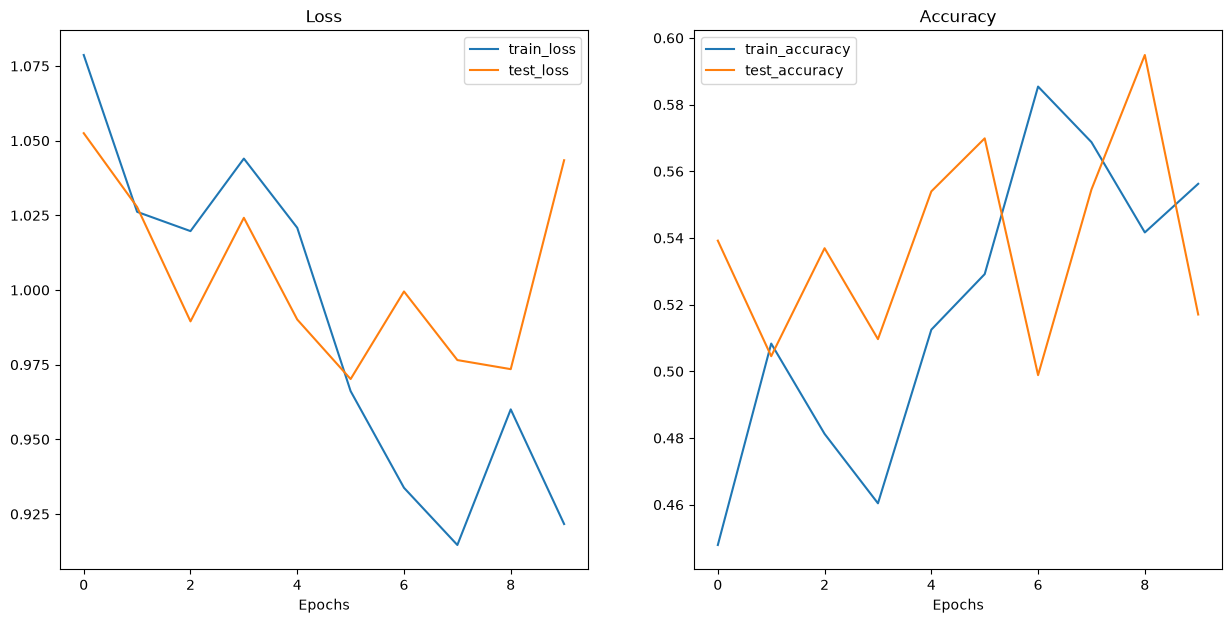

In [140]:
plot_loss_curves(results)

In [142]:
torch.manual_seed(21)
vit = ViT(num_classes=len(class_names)).to(device)

decay, no_decay = [], []
for name, p in vit.named_parameters():
    if p.ndim < 2 or name.endswith(NO_DECAY_NAMES):
        no_decay.append(p)
    else:
        decay.append(p)

optimizer = torch.optim.AdamW([{"params": decay,    "weight_decay": 0.1},
                               {"params": no_decay, "weight_decay": 0.0}],
                              lr=1e-3)

torch.manual_seed(21)   # reseed HERE — matches where the 3e-5 cell seeds
results_1e3 = engine.train(model=vit, train_dataloader=train_dataloader, test_dataloader=test_dataloader,
                           optimizer=optimizer, loss_fn=loss_fn, epochs=10, device=device)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.1727 | train_acc: 0.3833 | test_loss: 1.1729 | test_acc: 0.3500
Epoch: 2 | train_loss: 1.1783 | train_acc: 0.3229 | test_loss: 1.1113 | test_acc: 0.2875
Epoch: 3 | train_loss: 1.1103 | train_acc: 0.3312 | test_loss: 1.1149 | test_acc: 0.3625
Epoch: 4 | train_loss: 1.1155 | train_acc: 0.3312 | test_loss: 1.0979 | test_acc: 0.3625
Epoch: 5 | train_loss: 1.1335 | train_acc: 0.3000 | test_loss: 1.0994 | test_acc: 0.3500
Epoch: 6 | train_loss: 1.1716 | train_acc: 0.3458 | test_loss: 1.2597 | test_acc: 0.2875
Epoch: 7 | train_loss: 1.1486 | train_acc: 0.3021 | test_loss: 1.1535 | test_acc: 0.2875
Epoch: 8 | train_loss: 1.1275 | train_acc: 0.3667 | test_loss: 1.0950 | test_acc: 0.3625
Epoch: 9 | train_loss: 1.1149 | train_acc: 0.3042 | test_loss: 1.1048 | test_acc: 0.3500
Epoch: 10 | train_loss: 1.1150 | train_acc: 0.3396 | test_loss: 1.1475 | test_acc: 0.2875


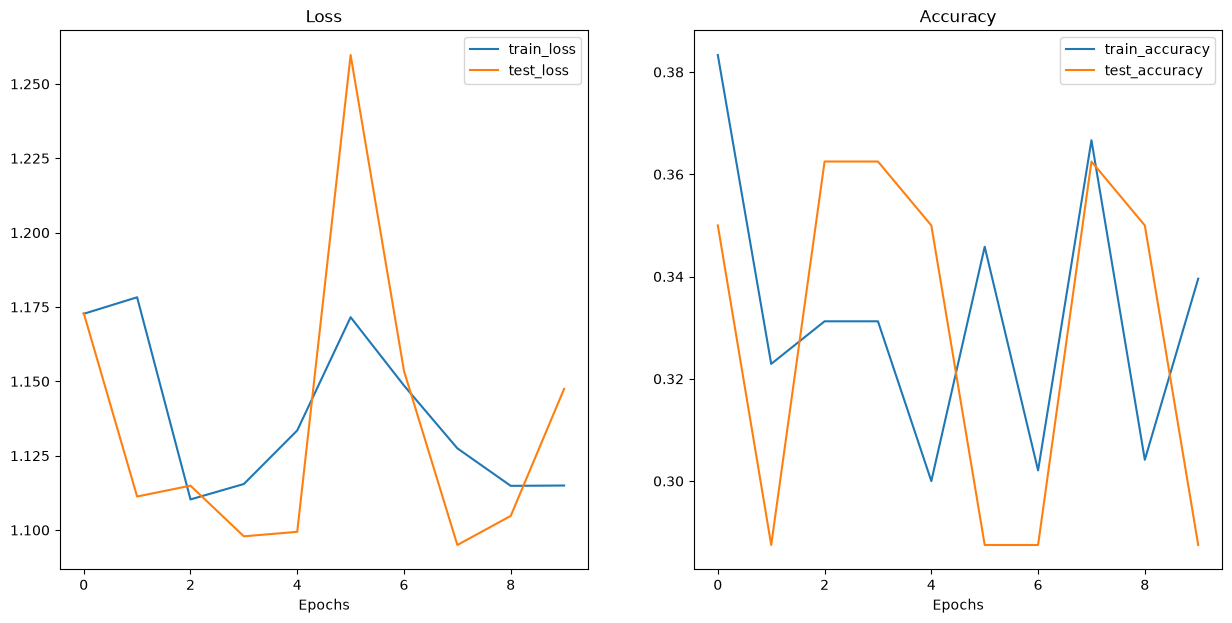

In [143]:
plot_loss_curves(results_1e3)

In [144]:
print(vit.positional_embedding.std().item())  
print(vit.class_embedding.std().item())

0.02301454171538353
0.010839775204658508


## 11. Use the power of transfer learning
* **Use pre-trained weights of ViT from **`torchvision.models`**.**
* **Let's experiment how the pre trained weights works on our data**

In [150]:
pretrained_vit_weights = torchvision.models.ViT_B_16_Weights.DEFAULT

#Setup a Vit model instance 
pretrained_vit = torchvision.models.vit_b_16(weights=pretrained_vit_weights).to(device)
pretrained_vit

VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine

In [151]:
# Freeze the base parameters 
for parameter in pretrained_vit.parameters():
    parameter.requires_grad=False

In [152]:
summary(model=pretrained_vit,
        input_size=(1, 3, 224, 224),    
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=21,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape           Output Shape          Param #               Trainable
VisionTransformer (VisionTransformer)                        [1, 3, 224, 224]      [1, 1000]             768                   False
├─Conv2d (conv_proj)                                         [1, 3, 224, 224]      [1, 768, 14, 14]      (590,592)             False
├─Encoder (encoder)                                          [1, 197, 768]         [1, 197, 768]         151,296               False
│    └─Dropout (dropout)                                     [1, 197, 768]         [1, 197, 768]         --                    --
│    └─Sequential (layers)                                   [1, 197, 768]         [1, 197, 768]         --                    False
│    │    └─EncoderBlock (encoder_layer_0)                   [1, 197, 768]         [1, 197, 768]         (7,087,872)           False
│    │    └─EncoderBlock (encoder_layer_1)                   [1, 197

In [153]:
#Update the MLP head to suit our problem to our class 
torch.manual_seed(21)
pretrained_vit.heads = nn.Linear(in_features=768, out_features=len(class_names)).to(device)

In [154]:
summary(model=pretrained_vit,
        input_size=(1, 3, 224, 224),    
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=21,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape           Output Shape          Param #               Trainable
VisionTransformer (VisionTransformer)                        [1, 3, 224, 224]      [1, 3]                768                   Partial
├─Conv2d (conv_proj)                                         [1, 3, 224, 224]      [1, 768, 14, 14]      (590,592)             False
├─Encoder (encoder)                                          [1, 197, 768]         [1, 197, 768]         151,296               False
│    └─Dropout (dropout)                                     [1, 197, 768]         [1, 197, 768]         --                    --
│    └─Sequential (layers)                                   [1, 197, 768]         [1, 197, 768]         --                    False
│    │    └─EncoderBlock (encoder_layer_0)                   [1, 197, 768]         [1, 197, 768]         (7,087,872)           False
│    │    └─EncoderBlock (encoder_layer_1)                   [1, 1

## 12. Train using pre-trained ViT model weights 
* **When using a pretrained model you want to make sure your data is formatted in the same way that the model was trained on.**
  * **The inference transforms are available at ViT_B_16_Weights.IMAGENET1K_V1.transforms and perform the following preprocessing operations: Accepts PIL.Image, batched (B, C, H, W) and single (C, H, W) image torch.Tensor objects. The images are resized to resize_size=[256] using interpolation=InterpolationMode.BILINEAR, followed by a central crop of crop_size=[224]. Finally the values are first rescaled to [0.0, 1.0] and then normalized using mean=[0.485, 0.456, 0.406] and std=[0.229, 0.224, 0.225].**
  * **This has been described in PyTorch - https://docs.pytorch.org/vision/main/models/generated/torchvision.models.vit_b_16.html**

In [155]:
# Get automatic transform from pretrained vit weights 
vit_transforms = pretrained_vit_weights.transforms()
vit_transforms

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

In [156]:
train_dataloader_vit , test_dataloader_vit, class_names = data_setup.create_dataloaders(train_dir=train_dir,
                                                                                       test_dir=test_dir,
                                                                                       transform=vit_transforms, batch_size=64,
                                                                                       num_workers=0)

### 12.1 Train feature extractor vit model 

In [158]:
torch.manual_seed(21)
optimizer = torch.optim.Adam(params=pretrained_vit.parameters(),
                            lr=1e-3, weight_decay=0.1)
loss_fn = loss_fn = torch.nn.CrossEntropyLoss()
results_vit = engine.train(model=pretrained_vit, train_dataloader=train_dataloader_vit, test_dataloader=test_dataloader_vit,
                      optimizer=optimizer, loss_fn=loss_fn, epochs=10, device=device)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.7682 | train_acc: 0.6953 | test_loss: 0.4436 | test_acc: 0.8968
Epoch: 2 | train_loss: 0.4500 | train_acc: 0.8314 | test_loss: 0.2721 | test_acc: 0.9427
Epoch: 3 | train_loss: 0.2852 | train_acc: 0.9199 | test_loss: 0.2297 | test_acc: 0.9332
Epoch: 4 | train_loss: 0.2281 | train_acc: 0.9453 | test_loss: 0.1926 | test_acc: 0.9384
Epoch: 5 | train_loss: 0.2014 | train_acc: 0.9473 | test_loss: 0.1712 | test_acc: 0.9384
Epoch: 6 | train_loss: 0.1935 | train_acc: 0.9531 | test_loss: 0.1612 | test_acc: 0.9384
Epoch: 7 | train_loss: 0.1673 | train_acc: 0.9551 | test_loss: 0.1526 | test_acc: 0.9437
Epoch: 8 | train_loss: 0.1532 | train_acc: 0.9570 | test_loss: 0.1514 | test_acc: 0.9384
Epoch: 9 | train_loss: 0.1890 | train_acc: 0.9609 | test_loss: 0.1546 | test_acc: 0.9332
Epoch: 10 | train_loss: 0.1886 | train_acc: 0.9193 | test_loss: 0.1531 | test_acc: 0.9332


In [159]:
print(sum(p.numel() for g in optimizer.param_groups for p in g["params"]), len(train_data))

85800963 450


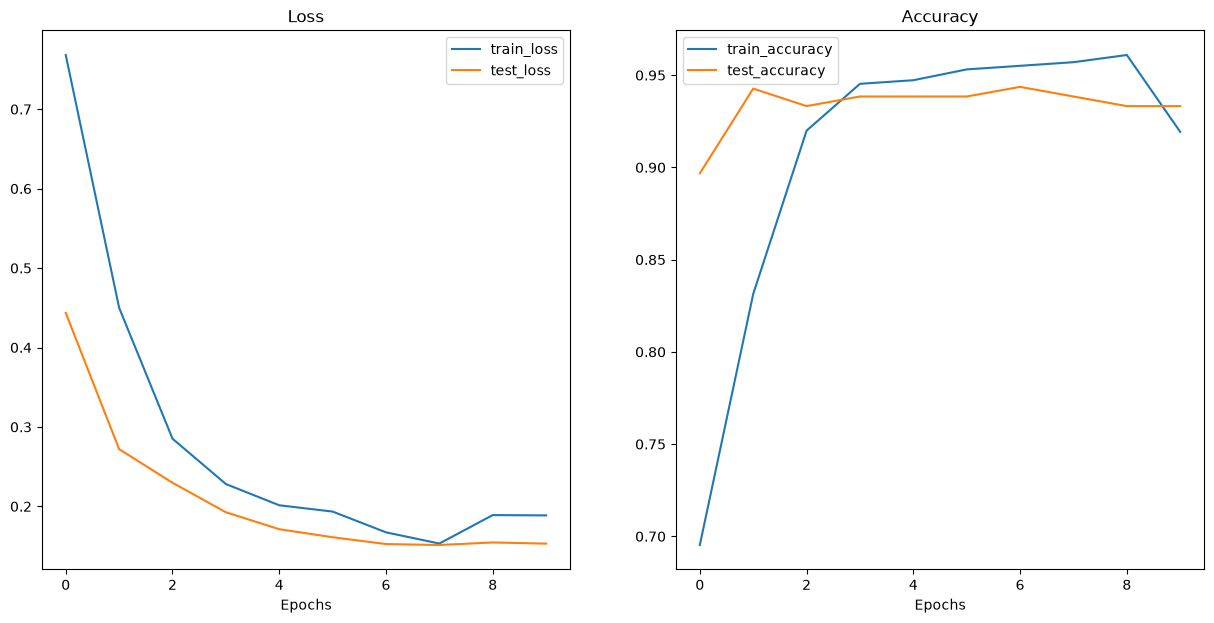

In [160]:
plot_loss_curves(results_vit)

## 13. Saving the Model

In [170]:
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)
MODEL_NAME = "07_pytorch_VisionTransformer_model.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME
MODEL_SAVE_PATH

WindowsPath('models/07_pytorch_VisionTransformer_model.pth')

In [171]:
torch.save(obj=pretrained_vit.state_dict(), f=MODEL_SAVE_PATH)

In [163]:
pretrained_vit.state_dict()

OrderedDict([('class_token',
              tensor([[[-1.1816e-03,  2.7023e-03,  2.5492e-03, -1.0183e-03, -6.8836e-04,
                        -7.0989e-03, -1.0262e-03, -5.0719e-04, -3.4578e-04,  7.2080e-04,
                        -1.2402e-03,  7.5692e-03, -7.7170e-04, -4.8869e-04, -3.9637e-03,
                        -1.4612e-03, -1.1996e-03, -6.3172e-04, -1.0178e-03, -6.6078e-04,
                        -1.0705e-03, -6.4979e-03, -7.7540e-04, -6.0426e-04, -7.3446e-04,
                        -3.1418e-03, -7.1227e-03, -1.0940e-03, -2.3099e-03, -7.0811e-04,
                        -8.9314e-04, -5.3678e-04,  7.4808e-03, -3.7627e-04, -1.5883e-03,
                        -7.2012e-04, -2.4297e-04, -6.3393e-04, -7.0300e-04, -6.7053e-04,
                         4.7179e-03, -7.9351e-04,  2.6560e-03, -1.0116e-03,  2.9899e-03,
                        -8.4867e-04, -5.3730e-03, -5.1106e-04,  5.5209e-03, -7.5487e-04,
                        -4.7614e-04, -2.3371e-03, -1.0001e-02, -5.9229e-04,  3.36

## 14. Predicting an Custom Image

In [164]:
# 1. Take in a trained model, class names, image path, image size, a transform and target device
def pred_and_plot_image(model,
                        image_path,
                        class_names,
                        image_size=(224, 224),
                        transform=None,
                        device=device):

    # 2. Open image (convert to RGB so PNGs with alpha / grayscale JPEGs don't break the model)
    img = Image.open(image_path).convert("RGB")

    # 3. Create transformation for image (if one doesn't exist)
    if transform is not None:
        image_transform = transform
    else:
        image_transform = transforms.Compose([
            transforms.Resize(256),
            transforms.CenterCrop(image_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225]),
        ])

    ### Predict on image ###

    # 4. Make sure the model is on the target device
    model.to(device)

    # 5. Turn on model evaluation mode and inference mode
    model.eval()
    with torch.inference_mode():
        # 6. Transform and add an extra dimension to image (model requires samples in [batch_size, color_channels, height, width])
        transformed_image = image_transform(img).unsqueeze(dim=0)

        # 7. Make a prediction on image with an extra dimension and send it to the target device
        target_image_pred = model(transformed_image.to(device))

    # 8. Convert logits -> prediction probabilities (using torch.softmax() for multi-class classification)
    target_image_pred_probs = torch.softmax(target_image_pred, dim=1)

    # 9. Convert prediction probabilities -> prediction labels
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1).item()

    # 10. Plot image with predicted label and probability
    plt.figure()
    plt.imshow(img)
    plt.title(f"Pred: {class_names[target_image_pred_label]} | "
              f"Prob: {target_image_pred_probs.max():.3f}")
    plt.axis(False);

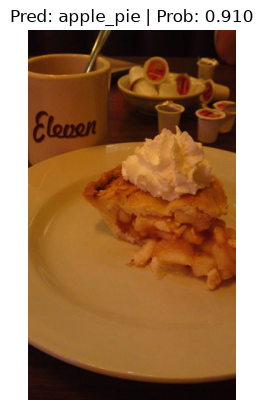

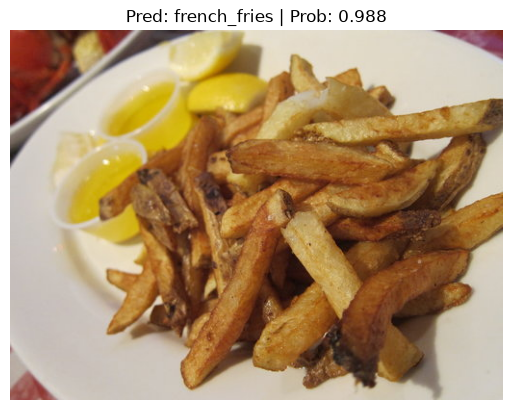

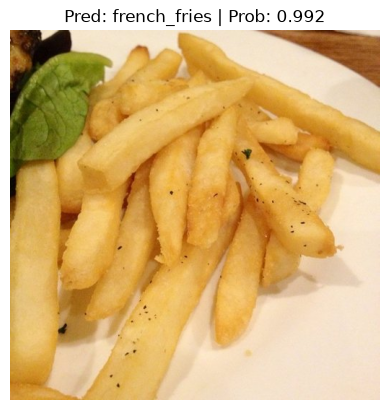

In [167]:
import random
num_images_to_plot = 3
test_image_path_list = list(Path(test_dir).glob("*/*.jpg")) # get list all image paths from test data 
test_image_path_sample = random.sample(population=test_image_path_list, # go through all of the test image paths
                                       k=num_images_to_plot) # randomly select 'k' image paths to pred and plot

# Make predictions on and plot the images
for image_path in test_image_path_sample:
    pred_and_plot_image(model=pretrained_vit, 
                        image_path=image_path,
                        class_names=class_names,
                        transform=vit_transforms)

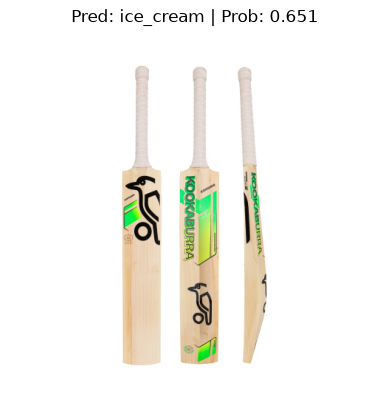

In [168]:
pred_and_plot_image(model=pretrained_vit,
                    image_path="images/middle_CRK-BAT-RPL-ACA-S-26.jpg",
                    class_names=class_names,
                    transform=vit_transforms)